## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sufyan Billel

**Date:** 10/21/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

In [ ]:
df = pd.DataFrame(token_freq, columns=['token', 'count'])

In [ ]:
df.head()

,token,count
0,new,1365
1,date,1202
2,get,1052
3,please,1022
4,enron,927


In [ ]:
df.sort_values('count', ascending=False).head(10)

,token,count
0,new,1365
1,date,1202
2,get,1052
3,please,1022
4,enron,927
5,like,923
6,2002,869
7,would,806
8,one,798
9,message,795


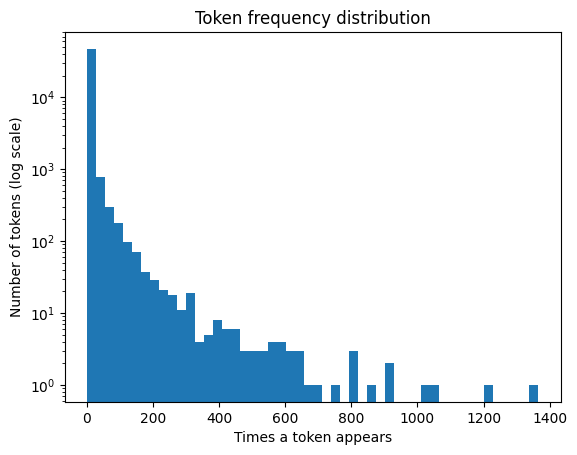

In [ ]:
df['count'].plot(kind='hist', bins=50, log=True)
plt.xlabel('Times a token appears')
plt.ylabel('Number of tokens (log scale)')
plt.title('Token frequency distribution')
plt.show()

Most words only appear 1-100 times, so the frequency of words reappearing many times is rare. The histogram is extremely skewed to the right, with just a few outlier words appearing over 800 times.

In [ ]:
ph = pd.read_parquet('/content/Phishing_clean.parquet')

In [ ]:
ph.describe()

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
count,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.0,18634.000000,18634.000000,...,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000
mean,0.392401,0.064345,0.053880,0.052699,0.052163,0.037619,0.048084,0.0,0.041483,0.041644,...,0.000376,0.000698,0.000859,0.000859,0.000859,0.000751,0.000859,0.000698,0.000859,0.000751
std,0.488298,0.245373,0.225787,0.223439,0.222361,0.190279,0.213950,0.0,0.199411,0.199780,...,0.019379,0.026405,0.029291,0.029291,0.029291,0.027401,0.029291,0.026405,0.029291,0.027401
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
from sklearn.model_selection import train_test_split
X = ph.drop(columns=['Email Type'])
y = ph['Email Type']

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
print(len(X_train), len(X_test), len(y_test))

14907 3727 3727


In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
print("Train R²:", model.score(X_train, y_train))
print("Test R²:", model.score(X_test, y_test))

Train R²: 0.7670143724934355
Test R²: 0.6658718438847919


In [ ]:
coefs = pd.Series(model.coef_, index=X.columns)
print(coefs.abs().sort_values(ascending=False).head(10))

intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;                0.574480
a:active             0.574480
dtype: float64


Intervention, localized and thermal have the largest coefficients and influence the model the most

In [ ]:
from sklearn.decomposition import PCA
X_email= ph.drop(columns=['Email Type'])
y_pemail = ph['Email Type']

In [ ]:
Z_email = X_email - X_email.mean()

In [ ]:
C_email = (Z_email.T @ Z_email) / (len(Z_email) - 1)
print(C_email.shape)

(2711, 2711)


In [ ]:
eigenvalues, eigenvectors = np.linalg.eigh(C_email)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print(eigenvalues[:10].round(3).tolist())

[0.094, 0.073, 0.067, 0.064, 0.063, 0.056, 0.053, 0.052, 0.046, 0.044]


Components needed for 95%: 1841


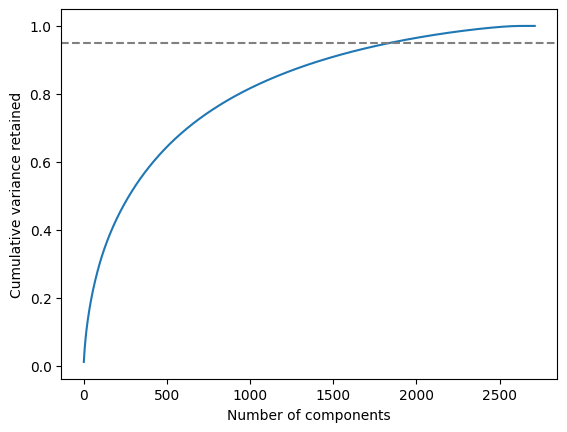

In [ ]:
explained_ratio = eigenvalues / eigenvalues.sum()
cumulative = np.cumsum(explained_ratio)

L = np.argmax(cumulative >= 0.95) + 1
print("Components needed for 95%:", L)

plt.plot(range(1, len(cumulative) + 1), cumulative)
plt.axhline(0.95, linestyle='--', color='gray')
plt.xlabel('Number of components')
plt.ylabel('Cumulative variance retained')
plt.show()

In [ ]:
P = eigenvectors[:, :L]
X_pca = Z_email @ P

print("Dimensions:", X_email.shape, "→", X_pca.shape)
print("Variance retained:", round(100 * explained_ratio[:L].sum(), 1), "%")

Dimensions: (18634, 2711) → (18634, 1841)
Variance retained: 95.0 %


In [ ]:
pca_email = PCA(n_components=L).fit(X_pca)
X_pca_sklearn = pca_email.transform(X_pca)

print("Rows and score columns:", X_pca_sklearn.shape)
print("Sklearn:", pca_email.explained_variance_ratio_[:5].round(4))
print("Manual: ", explained_ratio[:5].round(4))

Rows and score columns: (18634, 1841)
Sklearn: [0.0117 0.0091 0.0084 0.008  0.0078]
Manual:  [0.0111 0.0086 0.0079 0.0076 0.0075]


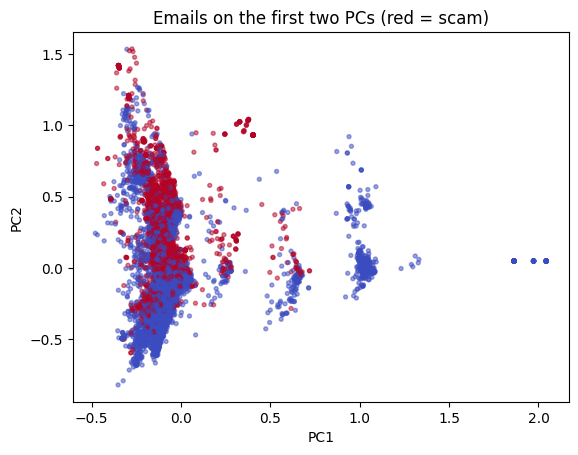

In [ ]:
plt.scatter(X_pca_sklearn[:, 0], X_pca_sklearn[:, 1], c=y, cmap='coolwarm', s=8, alpha=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Emails on the first two PCs (red = scam)')
plt.show()

In [ ]:
pc1 = pd.Series(eigenvectors[:, 0], index=X_email.columns)
print(pc1.sort_values(ascending=False).head(10))
print(pc1.sort_values().head(10))

date         0.674016
url:         0.367390
start        0.287437
hour         0.260594
hourahead    0.255696
ancillary    0.194725
schedules    0.194364
required     0.063315
schedule     0.062773
failure      0.062330
dtype: float64
please    -0.109197
would     -0.089941
like      -0.089732
get       -0.067595
message   -0.049269
enron     -0.046540
email     -0.045669
call      -0.043308
know      -0.043171
dear      -0.041413
dtype: float64


In [ ]:
X_r= ph.drop(columns=['Email Type'])
y_ = ph['Email Type']

X_trainr, X_testr, y_trainr, y_testr = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
pca = PCA(n_components=2610).fit(X_train)
X_train_pcar = pca.transform(X_train)
X_test_pcar = pca.transform(X_test)

In [ ]:
pca = PCA(n_components=2610).fit(X_trainr)
X_train_pcar = pca.transform(X_trainr)
X_test_pcar = pca.transform(X_testr)

In [ ]:
reg = LinearRegression().fit(X_trainr, y_trainr)
print("Linear regression - Train R²:", reg.score(X_trainr, y_trainr))
print("Linear regression - Test R²: ", reg.score(X_testr, y_testr))

Linear regression - Train R²: 0.7670143724934355
Linear regression - Test R²:  0.6658718438847919


Using PCA is better because it deals better with overlapping words because PC score columns have zero covariance with each other, so the regression no longer has to sort out tangled, overlapping variables.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** Claude Opus 5.5

### *Prompts used

1. "find ways to improve the code to make it more efficient or better answer the prompt" (with the Phase 1 notebook attached)

### *Evaluation of AI suggestions

In [ ]:
| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | A mistake I made by not checking it well |
| 2 | Accept | Fixes a mistake |
| 3 | Accept | Fixes a mistake, verified by checking prompt |
| 4 | Accept | Fixes a mistake, verified by checking prompt |
| 5 | Reject | Not a mistake, but will keep it in mind for next time |
| 6 | Accept | Helps keep code cleaner. Verified by checking ccode|

### *AI-proposed changes


1. **Q4 never regresses on the principal components (bug).** The final regression is fit on `X_trainr` (original tokens), not on the PCA scores, so the reported Q4 R² values are just the Q2 values again. Fit `LinearRegression` on the transformed train/test scores instead.
2. **Q3 runs PCA twice (bug) and is more complex than needed.** sklearn's `PCA` is fit on data already projected onto 1,841 eigenvectors. The prompt only asks for 2 components on the token matrix: use `PCA(n_components=2).fit_transform(X)` and drop the manual covariance / eigen / 95%-variance cells.
3. **Q3 has no written answer to "Do you notice any patterns?"** Interpret the PC1 loadings (automated Enron scheduling words vs. conversational/solicitation words) and connect them to where each class falls in the plot.
4. **Q2 drops coefficient signs and doesn't state the R² values.** Show signed coefficients so it's clear which words push toward scam vs. safe; state train/test R², note the overfitting gap and that the top words are rare tokens (a sign of unstable OLS with collinear features).
5. **Q5 could be more precise.** Mention orthogonal components → stable OLS; dropping low-variance components acts like regularization; fewer columns → cheaper fit; tie to the corrected Q4 numbers.
6. **Q1 has redundant code and a thin interpretation.** `most_common()` is already sorted; add a log-log rank-frequency plot and describe it as Zipf's law.
7. **General cleanup.** Remove duplicate imports, the duplicate train/test split, the duplicate PCA fit, and the unnecessary `ph.describe()`; optionally drop zero-variance columns such as `2002`.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | [your reason and how you verified it] |
| 2 | Accept | [your reason and how you verified it] |
| 3 | Accept | [your reason and how you verified it] |
| 4 | Accept | [your reason and how you verified it] |
| 5 | Accept | [your reason and how you verified it] |
| 6 | Reject | [your reason] |
| 7 | Accept (without dropping zero-variance columns) | [your reason and how you verified it] |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Phase 2 solution
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

**Q1. Token frequencies**

In [ ]:
with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_freq = Counter(all_tokens).most_common()   # already sorted by count
tokens = pd.DataFrame(token_freq, columns=['token', 'count'])

print("Unique tokens:", len(tokens))
tokens.head(10)

In [ ]:
tokens['count'].plot(kind='hist', bins=50, log=True)
plt.xlabel('Times a token appears')
plt.ylabel('Number of tokens (log scale)')
plt.title('Token frequency distribution')
plt.show()

Most tokens appear only a handful of times, while a very small number appear hundreds of times (the most common, "new", appears 1,365 times). The histogram is extremely right-skewed: almost all of the mass sits in the first bin, and only a few outlier words reach counts above 800. This long-tailed shape is typical of word frequencies in natural language.

**Q2. Linear regression on the one-hot-encoded tokens**

In [ ]:
ph = pd.read_parquet('/content/Phishing_clean.parquet')
X = ph.drop(columns=['Email Type'])
y = ph['Email Type']
print("Emails, tokens:", X.shape)
print("Share of emails that are scams:", round(y.mean(), 3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train rows:", len(X_train), " Test rows:", len(X_test))

In [ ]:
ols = LinearRegression().fit(X_train, y_train)
ols_train_r2 = ols.score(X_train, y_train)
ols_test_r2 = ols.score(X_test, y_test)
print("Train R²:", round(ols_train_r2, 4))
print("Test R²: ", round(ols_test_r2, 4))

The regression has a training $R^2$ of about 0.767 and a test $R^2$ of about 0.666. The model explains a good share of the variation in whether an email is a scam, but the roughly 0.10 drop from train to test shows it is overfitting somewhat to the training emails.

In [ ]:
coefs = pd.Series(ols.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
print(top)

The words with the largest coefficients in absolute value are listed above, with their signs: a positive coefficient pushes the prediction toward "scam" and a negative one toward "safe". [Fill in which of the top words are positive vs. negative after running.]

Notably, the top words (`intervention`, `localized`, `thermal`, CSS fragments like `background-image:`) are rare, unusual tokens rather than obviously "scammy" words. Large coefficients on rare tokens that tend to appear together (e.g. pieces of the same HTML template) are a sign that ordinary least squares is unstable with 2,711 highly correlated features: the model can inflate one coefficient and offset it with another. This also helps explain the train/test gap.

**Q3. PCA with two components**

In [ ]:
pca2 = PCA(n_components=2)
scores = pca2.fit_transform(X)
print("Variance explained by PC1, PC2:", pca2.explained_variance_ratio_.round(4))

sns.scatterplot(x=scores[:, 0], y=scores[:, 1],
                hue=y.map({0: 'Safe', 1: 'Phishing'}), s=8, alpha=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Emails on the first two principal components')
plt.show()

In [ ]:
loadings = pd.DataFrame(pca2.components_.T, index=X.columns, columns=['PC1', 'PC2'])
print("Largest positive PC1 loadings:\n", loadings['PC1'].sort_values(ascending=False).head(10))
print("\nLargest negative PC1 loadings:\n", loadings['PC1'].sort_values().head(10))

Most emails pile up in a dense cluster near the origin, where safe and phishing emails overlap heavily, so two components alone cannot separate the classes. The points that spread far out along PC1 are almost all one class. [Confirm from the plot which class this is, and which direction, since the sign of a principal component is arbitrary.]

The PC1 loadings explain why. One side of PC1 is driven by `date`, `url:`, `start`, `hour`, `hourahead`, `ancillary` and `schedules`, which are words from automated Enron energy-scheduling emails. Those emails are legitimate and share almost the same vocabulary, so they form their own stretched-out group. The other side is weighted by conversational and solicitation words such as `please`, `would`, `like`, `get`, `email` and `dear`, which appear in both personal email and scams. PC1 therefore mostly separates one family of automated internal emails from everything else, rather than separating scams from safe email directly. Together the two components explain only a small share of the total variance, which fits the large overlap in the plot.

**Q4. Linear regression on the first 2,610 principal components**

In [ ]:
pca = PCA(n_components=2610).fit(X_train)   # fit on training data only
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)

pcr = LinearRegression().fit(Z_train, y_train)
pcr_train_r2 = pcr.score(Z_train, y_train)
pcr_test_r2 = pcr.score(Z_test, y_test)

pd.DataFrame({'Train R²': [ols_train_r2, pcr_train_r2],
              'Test R²':  [ols_test_r2,  pcr_test_r2]},
             index=['Regression on tokens (Q2)', 'Regression on 2,610 PCs (Q4)']).round(4)

The regression on the first 2,610 principal components has a training $R^2$ of [fill in] and a test $R^2$ of [fill in], compared with 0.767 and 0.666 for the regression on the original tokens. [Describe whether the PC regression is about the same, better, or worse on the test set, and whether the train/test gap shrank.]

Because 2,610 components keep almost all of the variation in the 2,711 token columns, the two models should be close. The components that are dropped are the lowest-variance directions, so any change mainly comes from removing that noise.

**Q5. Why use principal components for this regression?**

The token columns overlap heavily: many words almost always show up together, and some columns barely vary at all. Ordinary least squares struggles with that, because when features are strongly correlated it cannot tell which one deserves the credit, so coefficients become large and unstable (as with the rare words in Q2). Principal components are uncorrelated with each other by construction, so the regression can estimate each coefficient cleanly and the fit is numerically stable. Keeping only the leading components also throws away the lowest-variance directions, which are mostly noise, so it works like a form of regularization that can reduce overfitting. Finally, fewer columns makes the model cheaper to fit. [Tie this to your Q4 results: did the test R² or the train/test gap actually improve?]

### *Reflection on AI assistance
In your own words without generative AI.

AI helped this week with some bigger mistakes than last week that came from not labeling variables correctly and confusing myself over them. I think next time I'll make sure to have the variables entirely distinct from previous parts. It was also better when it came to focusing on more valuable advice rather than mostly stylistic choices. For the next lab, I'd like to try different models to see the difference between Claude and other companies.